# Height and age at draft: do they predict beating your pick?

This notebook runs the analysis exactly as set out in the
[pre-registration](../docs/preregistration_height_age.md), which was committed
before any of these results were computed. Each section names the hypothesis
it tests. Anything that differs from the plan is marked **Deviation**.

**Question:** at a given pick number, do taller or older draftees do better or
worse than is typical for that pick?

In [1]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from afl.afltables import all_season_games
from afl.analysis import (bootstrap, expected_at_pick, games_before_draft,
                          games_in_window, slope, verdict)
from afl.draftguru import birth_dates, national_picks
from afl.match import load_manual_matches, match_picks

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(message)s")
pd.set_option("display.width", 200)

N_BOOT = 2000
MAX_PICK = 80

## 1. Data

- Matching uses AFL Tables seasons 2006–2026 (as validated in notebook 01), plus the reviewed manual matches.
- Seasons 1995–2005 are used **only** to count games played before the draft, for the recycled-player robustness check.
  The earliest possible debut among these picks is 1995.

In [2]:
picks = pd.concat([national_picks(year) for year in range(2005, 2019)], ignore_index=True)
picks = picks.merge(birth_dates(), on="draftguru_url", how="left")

seasons = all_season_games(2006, 2026)
early_seasons = all_season_games(1995, 2005)

matched = match_picks(picks, seasons, load_manual_matches())
print(matched["match_status"].value_counts().to_string())

df = matched[matched["pick"] <= MAX_PICK].copy()
df["age"] = (pd.to_datetime(df["draft_year"].astype(str) + "-11-30") - df["dob"]).dt.days / 365.25
df["mature_age"] = df["age"] >= 19.0
df["games_8"] = games_in_window(df, seasons, 8)
df["games_10"] = games_in_window(df, seasons, 10)
df["prior_games"] = games_before_draft(df, pd.concat([early_seasons, seasons]))

# Bid-matched picks: academies and father-sons, plus the earlier
# "Scholarship" and "Zone" concessions that worked the same way
df["bid_matched"] = df["signing"].str.match(r"(Academy|Father-Son|Scholarship|Zone)")

# Sanity checks: the window can never exceed all games after the draft,
# and for the 2018 draft the 8-season window covers everything to 2026
assert (df["games_8"] <= df["games_after_draft"]).all()
assert (df.loc[df["draft_year"] == 2018, "games_8"] == df.loc[df["draft_year"] == 2018, "games_after_draft"]).all()

print(f"\nPicks 1-{MAX_PICK}: {len(df)}  |  picks 41-80: {(df['pick'] > 40).sum()}")
print(f"Missing date of birth: {df['age'].isna().sum()}  |  mature-age (19.0+): {df['mature_age'].sum()}")
print(f"Bid-matched: {df['bid_matched'].sum()}  |  recycled (AFL games before draft): {(df['prior_games'] > 0).sum()}")

match_status
name            881
never played    117
name + club      17
manual           13

Picks 1-80: 1004  |  picks 41-80: 444
Missing date of birth: 1  |  mature-age (19.0+): 155
Bid-matched: 78  |  recycled (AFL games before draft): 23


**Deviation (clarification):** the plan said to exclude "academy and father-son
picks". DraftGuru also labels 2 picks "Scholarship" and 2 "Zone". These were the
earlier forms of the northern academy concessions and were bid-matched in the
same way, so they're excluded alongside the academy picks.

## 2. Outcome and baseline

- **Outcome:** games in the first 8 seasons after the draft.
- **Bust:** under 50 games in the window. **Massive bust:** under 20.
- **Baseline:** for each pick, the mean outcome of picks within ±2 of it.
- **Residual:** actual games minus that baseline.

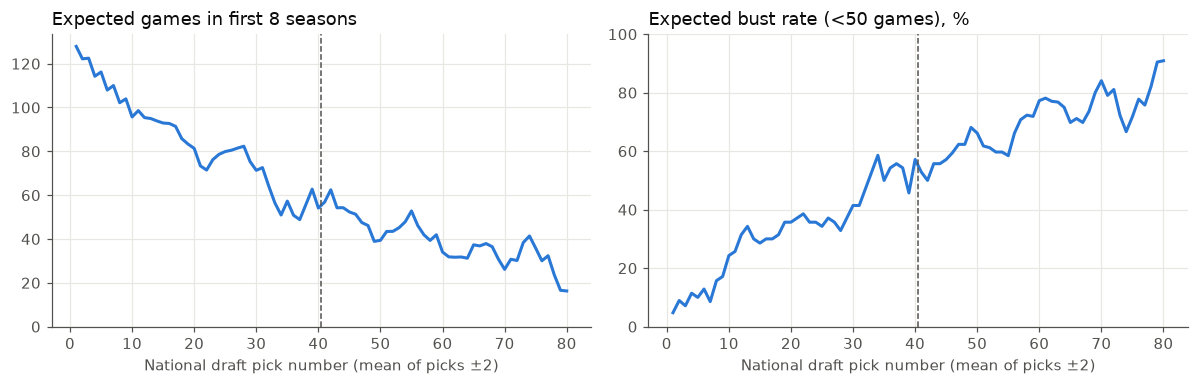

,expected_games,expected_bust
pick,,
1,127.88,0.05
10,95.69,0.24
20,81.34,0.36
30,71.33,0.41
40,54.11,0.57
50,39.40,0.66
60,34.03,0.77
70,26.14,0.84
80,16.27,0.91


In [3]:
def add_residuals(data, games_col, leave_one_out=False):
    """Add expected games, residual and bust residuals for outcome `games_col`."""
    data = data.copy()
    data["games"] = data[games_col]
    data["bust"] = (data["games"] < 50).astype(float)
    data["massive_bust"] = (data["games"] < 20).astype(float)
    for col in ["games", "bust", "massive_bust"]:
        data[f"expected_{col}"] = expected_at_pick(data, col, leave_one_out=leave_one_out)
        data[f"resid_{col}"] = data[col] - data[f"expected_{col}"]
    return data


d8 = add_residuals(df, "games_8")

# How the 8-season outcome falls with pick number (context for everything below)
by_pick = d8.groupby("pick")[["expected_games", "expected_bust"]].first()

GREY, BLUE, BLUE_BAND, ORANGE, INK = "#c3c2b7", "#2a78d6", "#cde2fb", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.8,
})

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(by_pick.index, by_pick["expected_games"], color=BLUE, linewidth=2)
axes[0].set_title("Expected games in first 8 seasons", loc="left", color="#0b0b0b")
axes[0].set_ylim(bottom=0)
axes[1].plot(by_pick.index, by_pick["expected_bust"] * 100, color=BLUE, linewidth=2)
axes[1].set_title("Expected bust rate (<50 games), %", loc="left", color="#0b0b0b")
axes[1].set_ylim(0, 100)
for ax in axes:
    ax.set_xlabel("National draft pick number (mean of picks ±2)")
    ax.axvline(40.5, color=INK, linewidth=1, linestyle="--")
plt.tight_layout()
plt.show()
by_pick.iloc[[0, 9, 19, 29, 39, 49, 59, 69, 79]].round(2)

## 3. H1 (primary): among picks 41–80, do taller players have lower residual games?

The test is the slope of residual games on height, reported per 5cm, with a 95% bootstrap interval.

In [4]:
def height_slope(data, col="resid_games"):
    return slope(data["height_cm"], data[col]) * 5  # per 5cm


late = d8[d8["pick"] > 40]
early = d8[d8["pick"] <= 40]

h1 = bootstrap(late, height_slope, n=N_BOOT)
print(f"H1  picks 41-80 (n={len(late)}): {h1[0]:+.1f} games per 5cm  "
      f"[95% CI {h1[1]:+.1f} to {h1[2]:+.1f}]")
print(f"    Pre-registered reading: {verdict(h1[1], h1[2])}")

H1  picks 41-80 (n=444): -2.5 games per 5cm  [95% CI -5.8 to +0.9]
    Pre-registered reading: inconclusive (interval includes 0)


In [5]:
BANDS = [0, 182, 189, 300]
BAND_LABELS = ["≤182cm", "183–189cm", "190cm+"]


def band_table(data):
    data = data.assign(height_band=pd.cut(data["height_cm"], BANDS, labels=BAND_LABELS))
    table = data.groupby("height_band", observed=True).agg(
        n=("pick", "size"),
        mean_pick=("pick", "mean"),
        games=("games", "mean"),
        expected=("expected_games", "mean"),
        resid=("resid_games", "mean"),
        bust_rate=("bust", "mean"),
        expected_bust=("expected_bust", "mean"),
        massive_bust_rate=("massive_bust", "mean"),
    )
    return table


print("Picks 41-80 by height band (games = first 8 seasons)")
band_table(late).round(2)

Picks 41-80 by height band (games = first 8 seasons)


,n,mean_pick,games,expected,resid,bust_rate,expected_bust,massive_bust_rate
height_band,,,,,,,,
≤182cm,119,57.17,51.39,42.60,8.79,0.61,0.67,0.44
183–189cm,159,56.99,35.19,41.51,-6.32,0.73,0.67,0.54
190cm+,166,58.36,39.80,40.59,-0.79,0.67,0.69,0.54


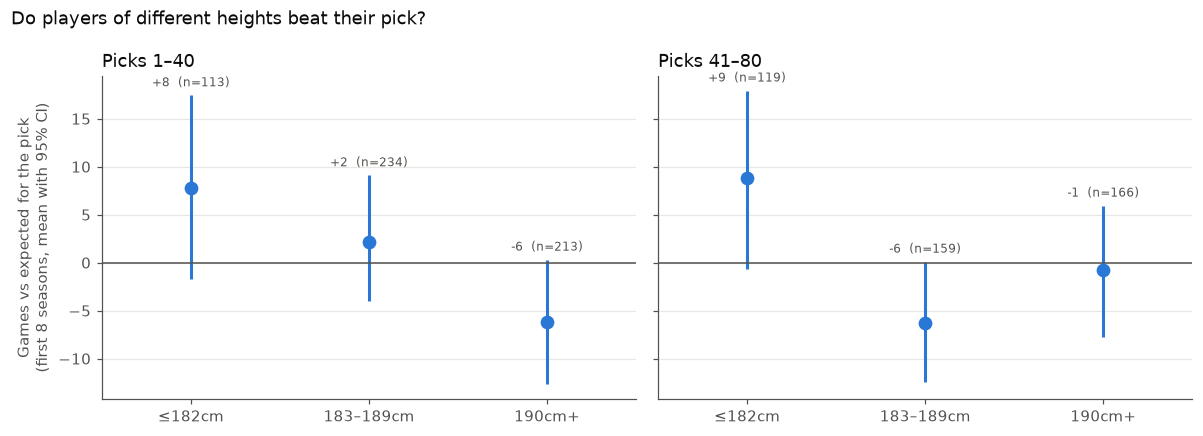

In [6]:
def band_means_with_ci(data, col="resid_games"):
    """Mean of `col` per height band, with a 95% bootstrap interval."""
    rows = []
    data = data.assign(height_band=pd.cut(data["height_cm"], BANDS, labels=BAND_LABELS))
    for label in BAND_LABELS:
        group = data[data["height_band"] == label]
        est, low, high = bootstrap(group, lambda g: g[col].mean(), n=N_BOOT)
        rows.append({"band": label, "mean": est, "low": low, "high": high, "n": len(group)})
    return pd.DataFrame(rows)


fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (title, data) in zip(axes, [("Picks 1–40", early), ("Picks 41–80", late)]):
    bands = band_means_with_ci(data)
    x = np.arange(len(bands))
    ax.errorbar(x, bands["mean"], yerr=[bands["mean"] - bands["low"], bands["high"] - bands["mean"]],
                fmt="o", color=BLUE, markersize=8, capsize=0, elinewidth=2)
    for xi, row in zip(x, bands.itertuples()):
        ax.annotate(f"{row.mean:+.0f}  (n={row.n})", (xi, row.high), xytext=(0, 6),
                    textcoords="offset points", ha="center", fontsize=8, color=INK)
    ax.axhline(0, color=INK, linewidth=1)
    ax.set_xticks(x, bands["band"])
    ax.set_xlim(-0.5, len(bands) - 0.5)
    ax.grid(axis="x", visible=False)
    ax.set_title(title, loc="left", color="#0b0b0b")
axes[0].set_ylabel("Games vs expected for the pick\n(first 8 seasons, mean with 95% CI)")
fig.suptitle("Do players of different heights beat their pick?", x=0.01, ha="left", color="#0b0b0b")
plt.tight_layout()
plt.show()

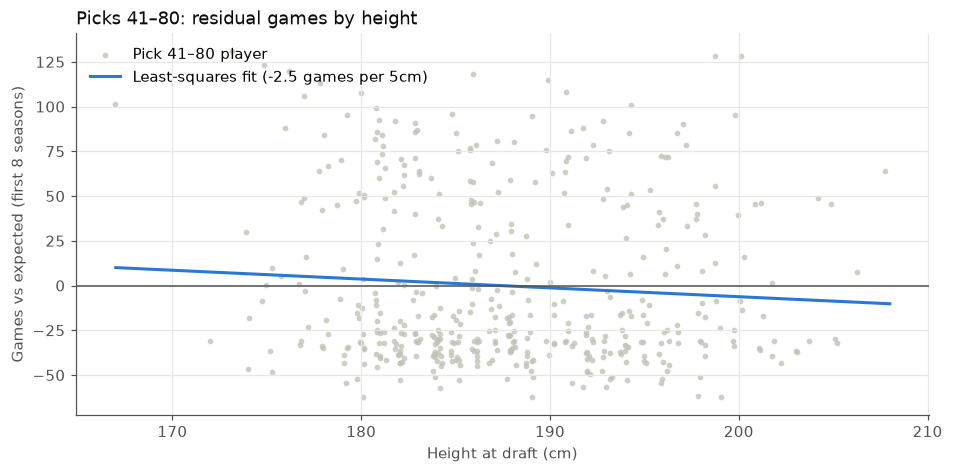

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
jitter = np.random.default_rng(1).uniform(-0.3, 0.3, len(late))
ax.scatter(late["height_cm"] + jitter, late["resid_games"], s=14, color=GREY, alpha=0.8,
           linewidths=0, label="Pick 41–80 player")
fit = np.polyfit(late["height_cm"], late["resid_games"], 1)
xs = np.array([late["height_cm"].min(), late["height_cm"].max()])
ax.plot(xs, np.polyval(fit, xs), color=BLUE, linewidth=2,
        label=f"Least-squares fit ({h1[0]:+.1f} games per 5cm)")
ax.axhline(0, color=INK, linewidth=1)
ax.set_xlabel("Height at draft (cm)")
ax.set_ylabel("Games vs expected (first 8 seasons)")
ax.set_title("Picks 41–80: residual games by height", loc="left", color="#0b0b0b")
ax.legend(frameon=False, loc="upper left")
plt.show()

### H1 secondary analyses

- **H1a:** the same slope for picks 1–40.
- **H1b:** bust and massive-bust rates for picks 41–80. The slope is in percentage points per 5cm; positive means taller players bust more often than their pick predicts.
- **H1c:** late development. The 10-season window (drafts 2005–2016) is compared with the 8-season window on **the same drafts**, so that only the window changes.

In [8]:
h1a = bootstrap(early, height_slope, n=N_BOOT)
print(f"H1a picks 1-40  (n={len(early)}): {h1a[0]:+.1f} games per 5cm  [95% CI {h1a[1]:+.1f} to {h1a[2]:+.1f}]")

h1b_bust = bootstrap(late, lambda d: height_slope(d, "resid_bust") * 100, n=N_BOOT)
h1b_massive = bootstrap(late, lambda d: height_slope(d, "resid_massive_bust") * 100, n=N_BOOT)
print(f"H1b picks 41-80 bust (<50):         {h1b_bust[0]:+.1f} pts per 5cm  "
      f"[95% CI {h1b_bust[1]:+.1f} to {h1b_bust[2]:+.1f}]")
print(f"H1b picks 41-80 massive bust (<20): {h1b_massive[0]:+.1f} pts per 5cm  "
      f"[95% CI {h1b_massive[1]:+.1f} to {h1b_massive[2]:+.1f}]")

# H1c: same drafts (2005-2016), 8 vs 10 seasons, baseline recomputed within those drafts
same_drafts = df[df["draft_year"] <= 2016]
late_8 = add_residuals(same_drafts, "games_8").query("pick > 40")
late_10 = add_residuals(same_drafts, "games_10").query("pick > 40")
h1c_8 = bootstrap(late_8, height_slope, n=N_BOOT)
h1c_10 = bootstrap(late_10, height_slope, n=N_BOOT)
print(f"\nH1c drafts 2005-2016, picks 41-80 (n={len(late_8)}):")
print(f"    8-season window:  {h1c_8[0]:+.1f} games per 5cm  [95% CI {h1c_8[1]:+.1f} to {h1c_8[2]:+.1f}]")
print(f"    10-season window: {h1c_10[0]:+.1f} games per 5cm  [95% CI {h1c_10[1]:+.1f} to {h1c_10[2]:+.1f}]")
moved = 1 - h1c_10[0] / h1c_8[0] if h1c_8[0] != 0 else float("nan")
print(f"    Movement towards 0: {moved:.0%} (the pre-registered flag is set off by more than 50%)")

H1a picks 1-40  (n=560): -3.7 games per 5cm  [95% CI -6.6 to -0.9]


H1b picks 41-80 bust (<50):         +1.0 pts per 5cm  [95% CI -2.2 to +4.2]
H1b picks 41-80 massive bust (<20): +1.8 pts per 5cm  [95% CI -1.5 to +5.1]



H1c drafts 2005-2016, picks 41-80 (n=368):
    8-season window:  -2.5 games per 5cm  [95% CI -6.3 to +1.5]
    10-season window: -2.7 games per 5cm  [95% CI -7.5 to +2.2]
    Movement towards 0: -8% (the pre-registered flag is set off by more than 50%)


## 4. H2 (secondary): age at draft

- **H2a:** juniors (under 19.0 on 30 November), picks 1–80. The slope of residual games on age, per 6 months. Negative means younger draftees beat their pick.
- **H2b:** mature-age (19.0+) vs juniors, picks 1–80. The difference in mean residual games, for both the 8- and 10-season windows.

One pick with no date of birth is left out.

In [9]:
with_age = d8[d8["age"].notna()]
juniors = with_age[~with_age["mature_age"]]
mature = with_age[with_age["mature_age"]]


def age_slope(data):
    return slope(data["age"], data["resid_games"]) * 0.5  # per 6 months


def mature_minus_junior(data):
    return (data.loc[data["mature_age"], "resid_games"].mean()
            - data.loc[~data["mature_age"], "resid_games"].mean())


h2a = bootstrap(juniors, age_slope, n=N_BOOT)
print(f"H2a juniors, picks 1-80 (n={len(juniors)}): {h2a[0]:+.1f} games per 6 months older  "
      f"[95% CI {h2a[1]:+.1f} to {h2a[2]:+.1f}]")

h2b_8 = bootstrap(with_age, mature_minus_junior, n=N_BOOT)
print(f"H2b mature-age (n={len(mature)}) minus junior, 8 seasons:  {h2b_8[0]:+.1f} games  "
      f"[95% CI {h2b_8[1]:+.1f} to {h2b_8[2]:+.1f}]")

d10 = add_residuals(df[(df["draft_year"] <= 2016) & df["age"].notna()], "games_10")
h2b_10 = bootstrap(d10, mature_minus_junior, n=N_BOOT)
print(f"H2b mature-age minus junior, 10 seasons (drafts 2005-2016): {h2b_10[0]:+.1f} games  "
      f"[95% CI {h2b_10[1]:+.1f} to {h2b_10[2]:+.1f}]")

H2a juniors, picks 1-80 (n=848): -2.2 games per 6 months older  [95% CI -7.3 to +2.6]


H2b mature-age (n=155) minus junior, 8 seasons:  +18.9 games  [95% CI +10.7 to +27.6]


H2b mature-age minus junior, 10 seasons (drafts 2005-2016): +20.8 games  [95% CI +9.2 to +33.9]


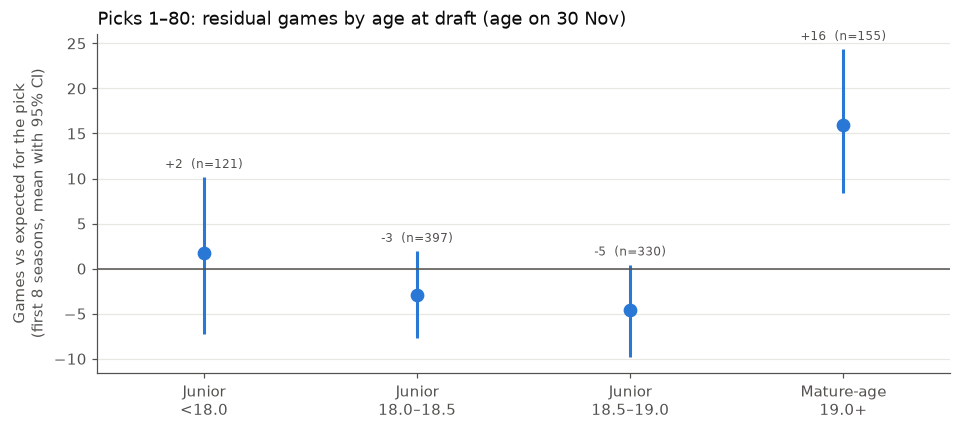

,mean,low,high,n,mean_pick
band,,,,,
Junior <18.0,1.7,-7.3,10.2,121,35.8
Junior 18.0–18.5,-2.9,-7.8,1.9,397,32.7
Junior 18.5–19.0,-4.6,-9.8,0.4,330,35.2
Mature-age 19.0+,16.0,8.4,24.3,155,51.9


In [10]:
AGE_BANDS = [0, 18.0, 18.5, 19.0, 100]
AGE_LABELS = ["Junior\n<18.0", "Junior\n18.0–18.5", "Junior\n18.5–19.0", "Mature-age\n19.0+"]
aged = with_age.assign(age_band=pd.cut(with_age["age"], AGE_BANDS, right=False, labels=AGE_LABELS))

rows = []
for label in AGE_LABELS:
    group = aged[aged["age_band"] == label]
    est, low, high = bootstrap(group, lambda g: g["resid_games"].mean(), n=N_BOOT)
    rows.append({"band": label, "mean": est, "low": low, "high": high, "n": len(group),
                 "mean_pick": group["pick"].mean()})
age_bands = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(age_bands))
ax.errorbar(x, age_bands["mean"], yerr=[age_bands["mean"] - age_bands["low"], age_bands["high"] - age_bands["mean"]],
            fmt="o", color=BLUE, markersize=8, capsize=0, elinewidth=2)
for xi, row in zip(x, age_bands.itertuples()):
    ax.annotate(f"{row.mean:+.0f}  (n={row.n})", (xi, row.high), xytext=(0, 6),
                textcoords="offset points", ha="center", fontsize=8, color=INK)
ax.axhline(0, color=INK, linewidth=1)
ax.set_xticks(x, age_bands["band"])
ax.set_xlim(-0.5, len(age_bands) - 0.5)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Games vs expected for the pick\n(first 8 seasons, mean with 95% CI)")
ax.set_title("Picks 1–80: residual games by age at draft (age on 30 Nov)", loc="left", color="#0b0b0b")
plt.show()
age_bands.drop(columns="band").assign(band=[l.replace("\n", " ") for l in AGE_LABELS]).set_index("band").round(1)

## 5. Robustness checks

Each check re-runs the main estimates on a changed dataset. When picks are
excluded, the baseline is recomputed from the remaining picks, so players are
still compared with similar players.

In [11]:
def estimates(data):
    """The main estimates, each as (estimate, low, high)."""
    late, early = data[data["pick"] > 40], data[data["pick"] <= 40]
    aged = data[data["age"].notna()]
    return {
        "H1  height, picks 41-80 (games/5cm)": bootstrap(late, height_slope, n=N_BOOT),
        "H1a height, picks 1-40 (games/5cm)": bootstrap(early, height_slope, n=N_BOOT),
        "H1b bust, picks 41-80 (pts/5cm)": bootstrap(late, lambda d: height_slope(d, "resid_bust") * 100, n=N_BOOT),
        "H2a age, juniors (games/6 months)": bootstrap(aged[~aged["mature_age"]], age_slope, n=N_BOOT),
        "H2b mature minus junior (games)": bootstrap(aged, mature_minus_junior, n=N_BOOT),
    }


variants = {
    "As planned": d8,
    "Excl. bid-matched picks": add_residuals(df[~df["bid_matched"]], "games_8"),
    "Excl. recycled players": add_residuals(df[df["prior_games"] == 0], "games_8"),
    "Leave-one-out baseline": add_residuals(df, "games_8", leave_one_out=True),
}

rows = []
for name, data in variants.items():
    for test, (est, low, high) in estimates(data).items():
        rows.append({"variant": name, "test": test,
                     "estimate": f"{est:+.1f} [{low:+.1f}, {high:+.1f}]",
                     "includes 0": low <= 0 <= high})
robust = pd.DataFrame(rows)
robust.pivot(index="test", columns="variant", values="estimate")[list(variants)]

variant,As planned,Excl. bid-matched picks,Excl. recycled players,Leave-one-out baseline
test,,,,
"H1 height, picks 41-80 (games/5cm)","-2.5 [-5.8, +0.9]","-2.5 [-5.9, +0.7]","-2.9 [-6.5, +0.8]","-2.5 [-5.9, +0.9]"
"H1a height, picks 1-40 (games/5cm)","-3.7 [-6.6, -0.9]","-3.8 [-6.9, -0.7]","-3.7 [-6.7, -0.8]","-3.8 [-6.7, -0.9]"
"H1b bust, picks 41-80 (pts/5cm)","+1.0 [-2.2, +4.2]","+0.9 [-2.4, +4.1]","+1.5 [-1.8, +4.9]","+1.0 [-2.3, +4.3]"
"H2a age, juniors (games/6 months)","-2.2 [-7.3, +2.6]","-2.3 [-7.4, +2.9]","-2.3 [-7.4, +2.6]","-2.3 [-7.5, +2.7]"
H2b mature minus junior (games),"+18.9 [+10.7, +27.6]","+20.7 [+11.7, +29.7]","+22.9 [+13.4, +32.3]","+19.2 [+10.9, +28.0]"


In [12]:
robust.pivot(index="test", columns="variant", values="includes 0")[list(variants)]

variant,As planned,Excl. bid-matched picks,Excl. recycled players,Leave-one-out baseline
test,,,,
"H1 height, picks 41-80 (games/5cm)",True,True,True,True
"H1a height, picks 1-40 (games/5cm)",False,False,False,False
"H1b bust, picks 41-80 (pts/5cm)",True,True,True,True
"H2a age, juniors (games/6 months)",True,True,True,True
H2b mature minus junior (games),False,False,False,False


## 6. Results

All intervals are 95% bootstrap intervals. "Games" means games in the first 8
seasons after the draft, compared with the mean for picks within ±2.

### Primary hypothesis

**H1 is inconclusive.** Among picks 41–80, each extra 5cm of height goes with
**2.5 fewer games** than the pick predicts, but the interval (−5.8 to +0.9)
includes zero. The direction matches the idea that clubs overrate tall late
picks, but this data can't separate that from chance. The result barely moves
across all three robustness checks (−2.5 to −2.9).

The height bands are uneven rather than a steady trend. Players 182cm and under
beat their pick by about 9 games, 183–189cm fell short by about 6, and 190cm+
were about level. These bands were for description only, so this pattern is
something to watch, not a finding.

### Secondary results

| Test | Estimate (95% CI) | Reading |
|---|---|---|
| H1a height, picks 1–40 | −3.7 games per 5cm (−6.6 to −0.9) | Interval excludes 0, in every robustness check |
| H1b bust rate, picks 41–80 | +1.0 pts per 5cm (−2.2 to +4.2) | Inconclusive |
| H1b massive bust, picks 41–80 | +1.8 pts per 5cm (−1.5 to +5.1) | Inconclusive |
| H1c 10 vs 8 seasons, picks 41–80 | −2.7 vs −2.5 games per 5cm | No sign that talls catch up in seasons 9–10 |
| H2a age, juniors, picks 1–80 | −2.2 games per 6 months older (−7.3 to +2.6) | Inconclusive |
| H2b mature-age minus junior, 8 seasons | **+18.9 games (+10.7 to +27.6)** | Interval well clear of 0, in every robustness check |
| H2b mature-age minus junior, 10 seasons | +20.8 games (+9.2 to +33.9) | Holds over a longer window |

**Mature-age draftees beat their pick clearly.** The 155 players aged 19+ at
the draft were taken at an average pick of 52. They averaged **63 games against
47 expected**, and **50% busted against 63% expected**. The edge isn't just
about being ready to play sooner: it holds over 10 seasons (+20.8). It also
isn't driven by recycled players, since excluding the 23 who had played AFL
before makes it larger (+22.9).

**Height may matter more at early picks than late ones.** Among picks 1–40,
taller players fell short of their pick (−3.7 games per 5cm). That's roughly 11
games between a 180cm and a 195cm player, against about 84 expected in this
range. It's the opposite of the "late picks" framing the hypothesis began with.

### How much weight to put on these

- Only H1 was pre-registered as the primary test. There were 8 secondary
  estimates, so at the 5% level one false positive among them wouldn't be
  surprising. The mature-age result (interval far from 0, stable across
  checks and both windows) is much more robust than the early-pick height result
  (upper end −0.9).
- These are associations at the same pick, not causes. Mature-age players are
  already proven in state leagues, so they may be a lower-risk type of player
  as well as being older.
- The bootstrap keeps each pick's baseline fixed, so the intervals are slightly
  too narrow.

### Possible next steps (not pre-registered, so they'd be exploratory)

1. **Mature-age in more depth:** does the edge depend on how they were found
   (state league vs a late bloomer from the under-18s), or on age bands within
   19+? Does it hold at early picks as well as late ones?
2. **Early-pick height:** is it about position (tall key-position players and
   rucks) or development (a 10-season window for picks 1–40)? Position would
   need to be inferred from AFL Tables stats.
3. **Turn the mature-age result into a pick-value statement:** how many pick
   slots is the mature-age edge "worth" on the expected-games curve?